# 03 - Competição entre dois algoritmos

**Etapa 4** | Fluxo: passos 6 e 7 (parcial)

* **Modelo A:** Regressão Logística (simples, interpretável). **Modelo B:** Random Forest.
* **Mesmas features** (as eleitas no notebook 02), **mesmo treino**, **mesmos folds** e **mesma métrica** (F1 macro).
* Na validação cruzada, cada fold usa as features **votadas dentro daquele fold** (sem vazamento) e o pré-processador
  ajustado só no treino do fold. O conjunto de teste **não é usado aqui**.
* Cada candidato é salvo como pipeline único: pré-processador + features eleitas + algoritmo.

In [1]:
# Preparação: localiza a raiz do projeto (o nbconvert executa com a pasta notebooks/ como diretório atual)
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

from src.config import carregar_config, p, dir_, ler_json, gravar_json
from src import ciclo, rastreio

cfg = carregar_config()
pd.set_option("display.width", 160, "display.max_columns", 30)

In [2]:
from src import features as ft, modelagem as mo
ctx = ciclo.carregar_contexto(cfg)
alvo = cfg["dados"]["alvo"]
proc = dir_(cfg, "dir_processed")
treino = pd.read_csv(proc / "treino.csv")
X_cols = ft.COLS_NUM + ft.COLS_CAT
X, y = treino[X_cols], treino[alvo]

eleitas_json = ler_json(proc / "features_eleitas.json")
folds_json = ler_json(proc / "votacao_folds.json")
for j in (eleitas_json, folds_json):   # integridade: a votação é deste mesmo ciclo e desta mesma versão de dados
    assert j["cycle_id"] == ctx["cycle_id"] and j["data_version"] == ctx["data_version"], "votação de outro ciclo!"
features = eleitas_json["features"]
print(ctx["cycle_id"], "|", len(features), "features eleitas")

C002_20261125T083010Z | 11 features eleitas


In [3]:
folds = ft.gerar_folds(y, cfg)
features_por_fold = [v["eleitas"] for v in folds_json["folds"]]
cv = mo.validar_cruzado(cfg, X, y, folds, features_por_fold)

tab_cv = pd.DataFrame({k: v["media"] for k, v in cv.items()}).T.round(4)
tab_cv["f1_macro_desvio"] = [round(cv[k]["desvio"]["f1_macro"], 4) for k in tab_cv.index]
tab_cv.insert(0, "algoritmo", [cfg["algoritmos"][k]["nome"] for k in tab_cv.index])
print(f"Validação cruzada estratificada ({cfg['avaliacao']['cv_folds']} folds), métrica principal: {cfg['avaliacao']['metrica']}")
tab_cv

Validação cruzada estratificada (5 folds), métrica principal: f1_macro


,algoritmo,f1_macro,accuracy,precision_macro,recall_macro,roc_auc,f1_macro_desvio
modelo_A,regressao_logistica,0.6656,0.7297,0.6605,0.7368,0.8213,0.0162
modelo_B,random_forest,0.6690,0.7445,0.6586,0.7205,0.8078,0.0261


## Ajuste final dos dois candidatos e registro no MLflow
Cada candidato é ajustado no treino completo com o conjunto eleito do ciclo e vira uma run com o **mesmo `cycle_id`**.

In [4]:
ev = ciclo.dir_evidencias(ctx); ev.mkdir(parents=True, exist_ok=True)
cand_dir = proc / "candidatos"; cand_dir.mkdir(exist_ok=True)
rastreio.configurar(cfg)

registro = {}
for chave, rot in (("modelo_A", "A"), ("modelo_B", "B")):
    spec = cfg["algoritmos"][chave]
    pipe = mo.treinar_final(cfg, chave, X, y, features)
    assert list(pipe.named_steps["sel"].colunas) == features      # A e B usam exatamente o mesmo conjunto
    f1_treino = mo.avaliar_pipeline(pipe, X, y)["f1_macro"]       # informativo (diagnóstico de sobreajuste)
    meta = {"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"], "chave": chave,
            "algoritmo": spec["nome"], "features": features, "seed": cfg["projeto"]["seed"]}
    caminho = mo.salvar_modelo(pipe, cand_dir / f"{ctx['cycle_id']}_{rot}.joblib", meta)

    with rastreio.run(f"{chave}_{spec['nome']}", ctx, etapa="treino_modelo",
                      tags_extra={"candidato": rot, "algoritmo": spec["nome"], "features_eleitas": ",".join(features)}) as r:
        mlflow.log_params({"algoritmo": spec["nome"], "seed": cfg["projeto"]["seed"], "n_features": len(features),
                           "cv_folds": cfg["avaliacao"]["cv_folds"], "metrica_principal": cfg["avaliacao"]["metrica"],
                           **{f"hp_{k}": v for k, v in spec["params"].items()}})
        mlflow.log_metrics({**{f"cv_{m}_media": v for m, v in cv[chave]["media"].items()},
                            **{f"cv_{m}_desvio": v for m, v in cv[chave]["desvio"].items()},
                            "treino_f1_macro": f1_treino})
        gravar_json(ev / f"cv_{chave}.json", cv[chave])
        mlflow.log_artifact(str(ev / f"cv_{chave}.json"))
        mlflow.log_artifact(str(caminho), artifact_path="modelo")
        registro[chave] = {"run_id": r.info.run_id, "caminho": str(caminho.relative_to(p())), "algoritmo": spec["nome"],
                           "f1_treino": f1_treino}
        ctx["run_ids"][chave] = r.info.run_id

gravar_json(proc / "resultados_cv.json", {"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"],
                                          "features": features, "cv": cv, "modelos": registro})
ciclo.salvar_contexto(cfg, ctx)
pd.DataFrame(registro).T

,run_id,caminho,algoritmo,f1_treino
modelo_A,5d399511c3a045f68b8ff044e92d3ea5,data/processed/candidatos/C002_20261125T083010...,regressao_logistica,0.67411
modelo_B,ee2221f2964346ad92c3df006deac126,data/processed/candidatos/C002_20261125T083010...,random_forest,0.764393


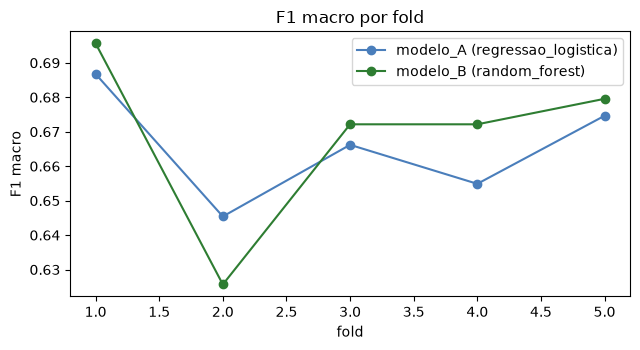

In [5]:
# Comparação visual dos folds (mesmos folds para A e B)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, cor in (("modelo_A", "#4a7ebb"), ("modelo_B", "#2e7d32")):
    ax.plot(range(1, len(cv[k]["por_fold"]) + 1), [f["f1_macro"] for f in cv[k]["por_fold"]], "o-", c=cor,
            label=f"{k} ({cfg['algoritmos'][k]['nome']})")
ax.set_xlabel("fold"); ax.set_ylabel("F1 macro"); ax.set_title("F1 macro por fold"); ax.legend()
plt.tight_layout(); plt.savefig(ev / "cv_por_fold.png", dpi=130); plt.show()